# Analysis results

Post-training analysis. This notebook reads the saved run JSON files and test-prediction CSV files.

Setup

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / 'results'
FIGURES_DIR = RESULTS_DIR / 'analysis_figures'
FIGURES_DIR.mkdir(exist_ok=True)
CONDITIONS = ['regular', 'augmented']
SEEDS = [0, 1, 2, 3, 4]
assert RESULTS_DIR.exists(), f'Results directory not found: {RESULTS_DIR}'

Read each saved run file and save the individual results as a CSV table.

In [2]:
records = []
for condition in CONDITIONS:
    for seed in SEEDS:
        run_name = f'{condition}_seed{seed}'
        result_path = RESULTS_DIR / f'{run_name}.json'
        if not result_path.exists():
            raise FileNotFoundError(result_path)
        result = json.loads(result_path.read_text())
        records.append({
            'condition': result['condition'],
            'seed': result['seed'],
            'best_step': result['best_step'],
            'best_val_loss': result['best_val_loss'],
            'test_loss': result['test_loss'],
            'test_accuracy': result['test_accuracy'],
            'minutes': result['minutes'],
        })

runs = pd.DataFrame(records).sort_values(['condition', 'seed']).reset_index(drop=True)
runs.to_csv(RESULTS_DIR / 'analysis_individual_runs.csv', index=False)
display(runs.style.format({'best_val_loss':'{:.4f}', 'test_loss':'{:.4f}', 'test_accuracy':'{:.4f}', 'minutes':'{:.1f}'}))

,condition,seed,best_step,best_val_loss,test_loss,test_accuracy,minutes
0,augmented,0,50,1.3613,1.3903,0.5564,19.9
1,augmented,1,100,1.1052,1.1161,0.6170,23.8
2,augmented,2,100,1.3118,1.2408,0.6057,23.4
3,augmented,3,300,1.2518,1.3519,0.6360,38.0
4,augmented,4,150,1.3103,1.2935,0.5904,27.5
5,regular,0,100,1.2076,1.2733,0.5809,22.9
6,regular,1,100,1.0270,1.0812,0.6272,23.6
7,regular,2,100,1.3036,1.3341,0.5641,23.2
8,regular,3,150,1.2237,1.2870,0.6104,27.0
9,regular,4,50,1.1855,1.2146,0.5929,19.6


## Individual-run comparison

Validation loss selected the checkpoint. Test metrics were calculated after that selection and are retained for every seed.

Calculate condition-level summaries and compare accuracy for matched seeds.

In [3]:
summary = runs.groupby('condition', sort=False)[['test_accuracy', 'test_loss']].agg(['mean', 'std'])
paired = runs.pivot(index='seed', columns='condition', values='test_accuracy')
paired['augmented_minus_regular'] = paired['augmented'] - paired['regular']
display(summary)
display(paired)
print(f"Mean paired accuracy difference: {paired['augmented_minus_regular'].mean():.4f}")

test_accuracy           test_loss          
                   mean       std      mean       std
condition                                            
augmented      0.601095  0.030021  1.278522  0.107110
regular        0.595108  0.024688  1.238042  0.097482

condition,augmented,regular,augmented_minus_regular
seed,,,
0,0.556407,0.580869,-0.024462
1,0.617014,0.627236,-0.010223
2,0.605695,0.564074,0.041621
3,0.635999,0.610442,0.025557
4,0.590361,0.592917,-0.002556


Mean paired accuracy difference: 0.0060


The augmented dataset accumulated a fractional higher mean test accuracy than the regular dataset. The regular dataset also had a lower test loss. This could be for various reasons one it could possibly be a signal that the augmented dataset generalises better.

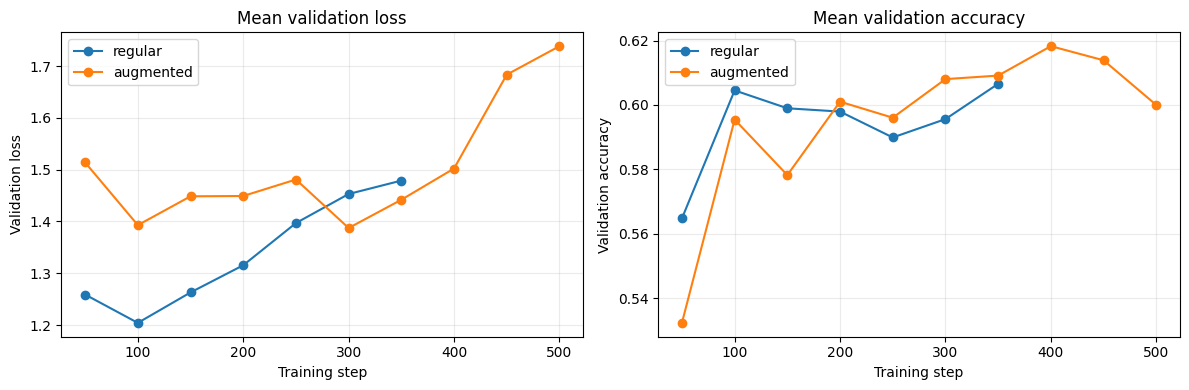

,mean,std
condition,,
augmented,140.0,96.176920
regular,100.0,35.355339


Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\validation_curves.png


In [4]:
history_rows = []
for condition in CONDITIONS:
    for seed in SEEDS:
        result = json.loads((RESULTS_DIR / f'{condition}_seed{seed}.json').read_text())
        for point in result['history']:
            history_rows.append({'condition': condition, 'seed': seed, **point})
history = pd.DataFrame(history_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for condition in CONDITIONS:
    mean_history = history.groupby(['condition', 'step'])[['val_loss', 'val_accuracy']].mean().loc[condition]
    axes[0].plot(mean_history.index, mean_history['val_loss'], marker='o', label=condition)
    axes[1].plot(mean_history.index, mean_history['val_accuracy'], marker='o', label=condition)

axes[0].set_title('Mean validation loss')
axes[0].set_ylabel('Validation loss')
axes[1].set_title('Mean validation accuracy')
axes[1].set_ylabel('Validation accuracy')
for ax in axes:
    ax.set_xlabel('Training step')
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
validation_path = FIGURES_DIR / 'validation_curves.png'
fig.savefig(validation_path, dpi=180, bbox_inches='tight')
plt.show()

best_steps = runs.groupby('condition')['best_step'].agg(['mean', 'std'])
display(best_steps)
print(f'Saved {validation_path}')

#### Validation Loss
The regular model starts with lower validation loss, reaching its lowest average loss at roughly 100 training steps.
Its loss then gradually increases, suggesting that training beyond this point may be causing overfitting.

The augmented model starts with a higher loss, improves early, and is briefly similar to the regular model around 300 steps.
After about 350 steps, the augmented model’s loss rises sharply, indicating that later training became worse rather than better.

#### Validation Accuracy
Both conditions reach validation accuracies around 0.59–0.62.
The augmented model catches up with, and sometimes exceeds, the regular model at later steps.
However, the improvement is small and inconsistent across the training curve. It does not show a fully stable upward advantage for augmentation.

Accuracy fluctuates while loss increases, which suggests that the model may still classify some examples correctly but is becoming increasingly uncertain or making more confident errors.

#### Conclusion
Both models learn useful features early, but continuing training does not consistently improve validation performance. Augmentation gives slightly better validation accuracy at some later checkpoints, but it also has higher and more unstable validation loss. Therefore, these curves do not provide strong evidence that augmentation improved training.

Plot test accuracy for each seed, with the condition mean and standard deviation.

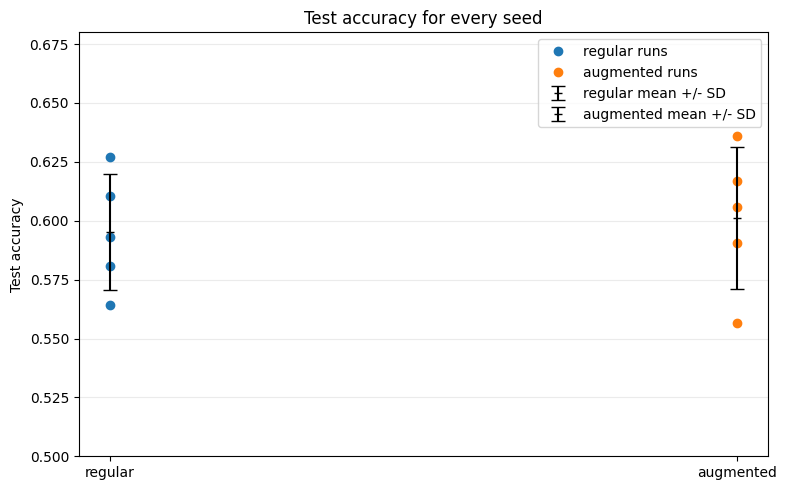

Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\test_accuracy_by_seed.png


In [5]:
means = runs.groupby('condition')['test_accuracy'].agg(['mean', 'std']).reindex(CONDITIONS)

fig, ax = plt.subplots(figsize=(8, 5))
for condition in CONDITIONS:
    values = runs.loc[runs['condition'] == condition, 'test_accuracy']
    ax.plot([condition] * len(values), values, 'o', label=f'{condition} runs')
    ax.errorbar(
        condition, means.loc[condition, 'mean'],
        yerr=means.loc[condition, 'std'],
        fmt='_', color='black', capsize=5,
        label=f'{condition} mean +/- SD',
    )

ax.set_ylabel('Test accuracy')
ax.set_title('Test accuracy for every seed')
ax.set_ylim(0.5, 0.68)
ax.grid(axis='y', alpha=0.25)
ax.legend()
fig.tight_layout()

figure_path = FIGURES_DIR / 'test_accuracy_by_seed.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {figure_path}')

This plot shows the test accuracy for every seed in both conditions, together with each condition's mean and standard deviation. The augmented mean is only slightly higher than the regular mean, and the points overlap substantially. This tells us that augmentation does not produce a clear or consistent overall accuracy improvement across the five seeds.

Show the paired accuracy change for each seed so consistency is visible rather than hidden by the average.

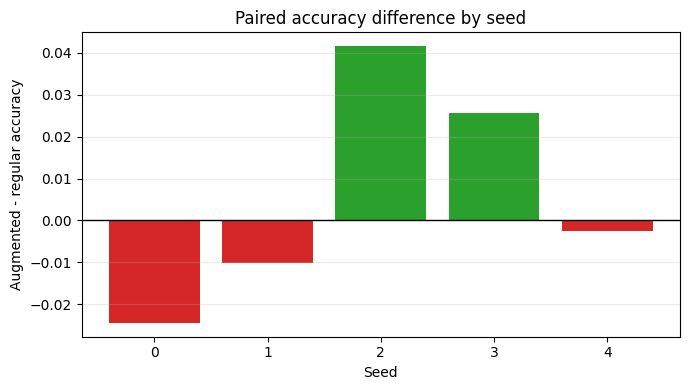

Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\paired_accuracy_difference.png


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
differences = paired['augmented_minus_regular']
colors = ['tab:green' if value >= 0 else 'tab:red' for value in differences]
ax.axhline(0, color='black', linewidth=1)
ax.bar(differences.index.astype(str), differences, color=colors)
ax.set_xlabel('Seed')
ax.set_ylabel('Augmented - regular accuracy')
ax.set_title('Paired accuracy difference by seed')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
paired_path = FIGURES_DIR / 'paired_accuracy_difference.png'
fig.savefig(paired_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {paired_path}')

Each bar shows how augmentation changed accuracy for the same seed. Positive bars mean augmentation helped; negative bars mean it hurt. The bars appear on both sides of zero, showing that the small average improvement is not consistent across seeds and should not be described as a reliable effect.

## Anomalies and failure cases

The class labels mean: `tom` = Tom in frame, `jerry` = Jerry in frame, `tom_jerry_0` = neither Tom nor Jerry in frame, and `tom_jerry_1` = both Tom and Jerry in frame. The confusion matrices and per-class table identify whether the overall metric hides class-specific failures.

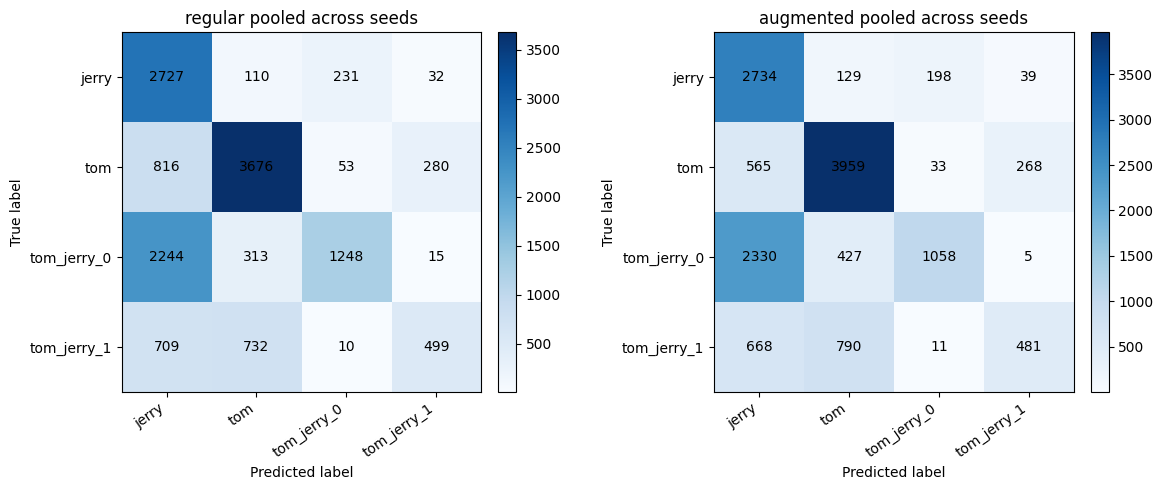

condition,augmented,regular
class,,
jerry,0.881935,0.879677
tom,0.820518,0.761865
tom_jerry_0,0.276963,0.326702
tom_jerry_1,0.246667,0.255897


Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\pooled_confusion_matrices.png


In [7]:
class_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, condition in zip(axes, CONDITIONS):
    frames = [pd.read_csv(RESULTS_DIR / f'{condition}_seed{seed}_test_predictions.csv') for seed in SEEDS]
    predictions = pd.concat(frames, ignore_index=True)
    classes = sorted(predictions['label'].unique())
    matrix = pd.crosstab(predictions['label'], predictions['predicted']).reindex(index=classes, columns=classes, fill_value=0).to_numpy()
    image = ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(classes)), classes, rotation=35, ha='right')
    ax.set_yticks(range(len(classes)), classes)
    for row in range(len(classes)):
        for column in range(len(classes)):
            ax.text(column, row, matrix[row, column], ha='center', va='center')
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(f'{condition} pooled across seeds')
    for label, group in predictions.groupby('label', sort=True):
        class_rows.append({'condition': condition, 'class': label, 'n_predictions': len(group), 'correct': (group['label'] == group['predicted']).sum(), 'accuracy': (group['label'] == group['predicted']).mean()})
fig.tight_layout()
confusion_path = FIGURES_DIR / 'pooled_confusion_matrices.png'
fig.savefig(confusion_path, dpi=180, bbox_inches='tight')
plt.show()
per_class = pd.DataFrame(class_rows)
per_class.to_csv(RESULTS_DIR / 'analysis_per_class_accuracy.csv', index=False)
display(per_class.pivot(index='class', columns='condition', values='accuracy'))
print(f'Saved {confusion_path}')

These pooled confusion matrices show which classes are predicted correctly and which are confused. The model recognises frames containing Tom or Jerry more successfully, while frames containing neither character and frames containing both characters are much harder. This reveals important class-specific failures that overall accuracy hides.

This text table breaks each class into true positives (TP), false positives (FP), false negatives (FN), and true negatives (TN). The counts use a one-vs-rest view: the selected class is treated as positive and all other classes as negative.

In [8]:
classification_rows = []
for condition in CONDITIONS:
    frames = [pd.read_csv(RESULTS_DIR / f'{condition}_seed{seed}_test_predictions.csv') for seed in SEEDS]
    predictions = pd.concat(frames, ignore_index=True)
    classes = sorted(predictions['label'].unique())
    total = len(predictions)
    for label in classes:
        actual_positive = predictions['label'] == label
        predicted_positive = predictions['predicted'] == label
        tp = (actual_positive & predicted_positive).sum()
        fp = (~actual_positive & predicted_positive).sum()
        fn = (actual_positive & ~predicted_positive).sum()
        tn = (~actual_positive & ~predicted_positive).sum()
        classification_rows.append({'condition': condition, 'class': label, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})

classification_counts = pd.DataFrame(classification_rows)
display(classification_counts)

,condition,class,TP,FP,FN,TN
0,regular,jerry,2727,3769,373,6826
1,regular,tom,3676,1155,1149,7715
2,regular,tom_jerry_0,1248,294,2572,9581
3,regular,tom_jerry_1,499,327,1451,11418
4,augmented,jerry,2734,3563,366,7032
5,augmented,tom,3959,1346,866,7524
6,augmented,tom_jerry_0,1058,242,2762,9633
7,augmented,tom_jerry_1,481,312,1469,11433


Compare per-class accuracy directly to show which classes gained or lost under augmentation.

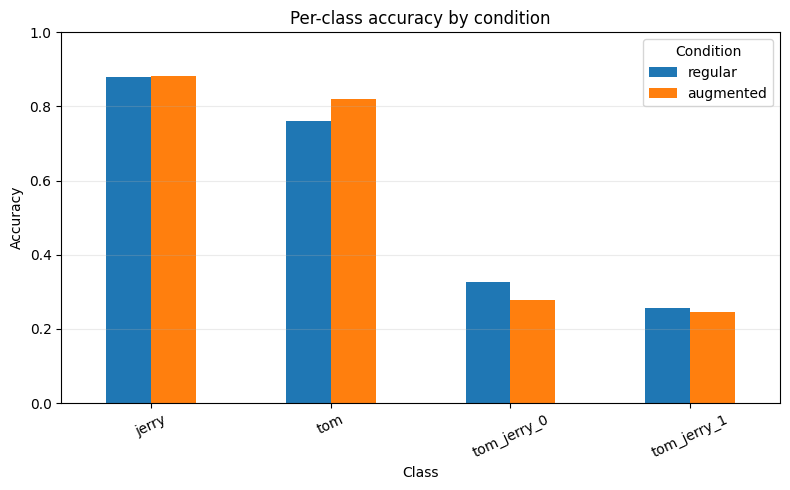

Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\per_class_accuracy.png


In [14]:
class_plot = per_class.pivot(index='class', columns='condition', values='accuracy').reindex(columns=CONDITIONS)
ax = class_plot.plot(kind='bar', figsize=(8, 5), rot=25)
ax.set_xlabel('Class')
ax.set_ylabel('Accuracy')
ax.set_title('Per-class accuracy by condition')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.25)
ax.legend(title='Condition')
fig = ax.get_figure()
fig.tight_layout()
class_path = FIGURES_DIR / 'per_class_accuracy.png'
fig.savefig(class_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {class_path}')

Augmentation improves the Tom class, but performance remains weak for frames containing neither character and frames containing both characters. The result suggests that augmentation may help one relatively recognisable class without solving the harder task of distinguishing the two special frame types.

Rank the most common mistakes across the pooled predictions to identify the main confusion pairs.

,label,predicted,count,condition
18,tom_jerry_0,jerry,2330,augmented
22,tom_jerry_1,tom,790,augmented
21,tom_jerry_1,jerry,668,augmented
15,tom,jerry,565,augmented
19,tom_jerry_0,tom,427,augmented
6,tom_jerry_0,jerry,2244,regular
3,tom,jerry,816,regular
10,tom_jerry_1,tom,732,regular
9,tom_jerry_1,jerry,709,regular
7,tom_jerry_0,tom,313,regular


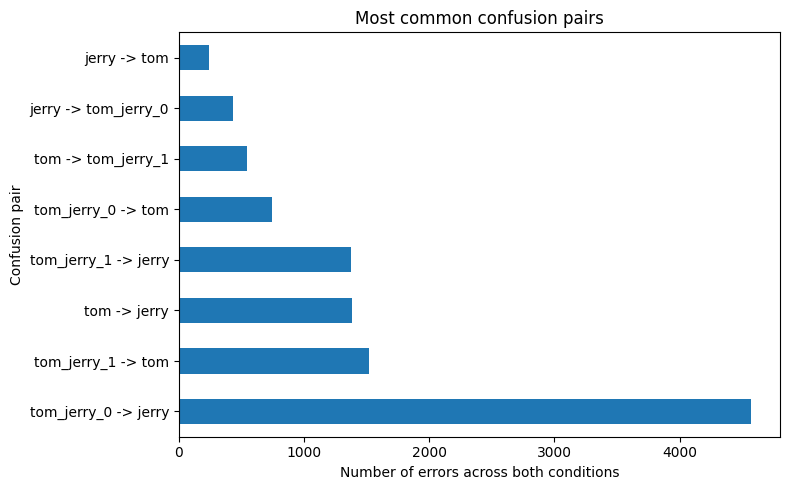

Saved c:\Users\Ellice\Repos\EoinClaw.ai\results\analysis_figures\common_confusion_pairs.png


In [15]:
confusion_rows = []
for condition in CONDITIONS:
    frames = [pd.read_csv(RESULTS_DIR / f'{condition}_seed{seed}_test_predictions.csv') for seed in SEEDS]
    predictions = pd.concat(frames, ignore_index=True)
    mistakes = predictions[predictions['label'] != predictions['predicted']]
    confusion_rows.append(
        mistakes.groupby(['label', 'predicted']).size().reset_index(name='count').assign(condition=condition)
    )
confusion_pairs = pd.concat(confusion_rows, ignore_index=True)
confusion_pairs = confusion_pairs.sort_values(['condition', 'count'], ascending=[True, False])
confusion_pairs.to_csv(RESULTS_DIR / 'analysis_common_confusion_pairs.csv', index=False)
display(confusion_pairs.groupby('condition', group_keys=False).head(5))

plot_data = confusion_pairs.groupby(['label', 'predicted'], as_index=False)['count'].sum().sort_values('count', ascending=False).head(8)
plot_data['pair'] = plot_data['label'] + ' -> ' + plot_data['predicted']
ax = plot_data.plot(kind='barh', x='pair', y='count', figsize=(8, 5), legend=False)
ax.set_xlabel('Number of errors across both conditions')
ax.set_ylabel('Confusion pair')
ax.set_title('Most common confusion pairs')
fig = ax.get_figure()
fig.tight_layout()
pairs_path = FIGURES_DIR / 'common_confusion_pairs.png'
fig.savefig(pairs_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {pairs_path}')

The most frequent pooled mistakes are especially frames containing neither character being predicted as Jerry or Tom. It confirms which errors dominate the dataset, but these are raw counts and are affected by class frequency. The per-class accuracy and normalised confusion matrix should therefore be used to judge class-specific performance.

## Current interpretation

Across five matched seeds, augmentation has a slightly higher mean test accuracy than the regular reference condition (about 0.601 versus 0.595), but the paired difference is small and changes direction across seeds. Augmentation also has a higher mean test loss (about 1.279 versus 1.238). The overall metrics therefore do not establish a reliable improvement in generalisation from augmentation.

The validation curves show useful learning early in training, followed by a plateau or deterioration rather than a steady improvement. Validation loss rises at later checkpoints, especially for the augmented condition, while validation accuracy fluctuates around the same level. This supports selecting the best validation checkpoint instead of using the final checkpoint. The test-loss plot and paired-difference plot also show that the small average accuracy advantage is not consistent across seeds.

The clearest failure is class-specific. Frames containing Tom or Jerry are classified much more accurately, while `tom_jerry_0` (neither character in frame) and `tom_jerry_1` (both characters in frame) are frequently confused with the single-character classes. The one-vs-rest TP/FP/FN/TN table makes this explicit: false negatives are high for the difficult classes, while false positives show that the model often predicts `tom` or `jerry` when the true image contains neither or both. The largest pooled error is `tom_jerry_0` being predicted as `jerry`, although raw counts are affected by class frequency. Overall accuracy therefore hides an important weakness in recognising the combined-character states, so the confusion matrices, per-class accuracy, and TP/FP/FN/TN counts should be reported alongside the run-level results.

Overall, augmentation appears broadly comparable to the regular condition, with a small but unreliable accuracy advantage and no clear improvement in loss or class-level robustness.